In [1]:
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets
from IPython.display import display
import pandas as pd
from imblearn.over_sampling import RandomOverSampler
import seaborn as sns

from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score,
)
from sklearn.utils.validation import check_is_fitted
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [2]:
# Framingham Heart Study dataset, commonly used for cardiovascular disease risk prediction. It typically includes demographics, behavioral factors, clinical measurements, and a binary target (10-year CHD risk).
df = pd.read_csv(r"D:\iit jammu internship\heart disease\framingham.csv")

In [3]:
df.head(10)

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0
5,0,43,2.0,0,0.0,0.0,0,1,0,228.0,180.0,110.0,30.30,77.0,99.0,0
6,0,63,1.0,0,0.0,0.0,0,0,0,205.0,138.0,71.0,33.11,60.0,85.0,1
7,0,45,2.0,1,20.0,0.0,0,0,0,313.0,100.0,71.0,21.68,79.0,78.0,0
8,1,52,1.0,0,0.0,0.0,0,1,0,260.0,141.5,89.0,26.36,76.0,79.0,0
9,1,43,1.0,1,30.0,0.0,0,1,0,225.0,162.0,107.0,23.61,93.0,88.0,0


In [4]:
df.tail(10)

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4230,0,56,1.0,1,3.0,0.0,0,1,0,268.0,170.0,102.0,22.89,57.0,NaN,0
4231,1,58,3.0,0,0.0,0.0,0,1,0,187.0,141.0,81.0,24.96,80.0,81.0,0
4232,1,68,1.0,0,0.0,0.0,0,1,0,176.0,168.0,97.0,23.14,60.0,79.0,1
4233,1,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0
4238,1,40,3.0,0,0.0,0.0,0,1,0,185.0,141.0,98.0,25.60,67.0,72.0,0
4239,0,39,3.0,1,30.0,0.0,0,0,0,196.0,133.0,86.0,20.91,85.0,80.0,0


In [5]:
df.shape #(Number of Rows, Number of Columns)

(4240, 16)

In [6]:
df.isnull().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

In [7]:
x = df.drop(columns = "TenYearCHD")
y = df.TenYearCHD

# Splitting the dataset into Training data and Testing Data in the ratio 8:2.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42, stratify = y)

# Splitting the Training data further into Training data and Validation Data in the ratio 8:2.
# So, final ratios are: Training Data -> 80% of 80%  = 64 %, Testing Data = 20 %, Validation Data -> 20% of 80% = 16 %.
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size = 0.2, random_state = 42, stratify = y_train)

**USE OF STRATIFY = Y and STRATIFY = Y_TRAIN**

It keeps the same class proportion in every split (train / validation / test) as in the original dataset.

**WHAT HAPPENS WHEN WE DON'T USE STRATIFY?**

Imagine a dataset of 100 patients in which O(No CHD) are 85 and 1(CHD) is 15.

That’s 85% negative, 15% positive.

Now when we train our model on data which is split without using stratification, the test split of 20 entries will give let's say 19 0(No CHD) and 1(CHD) because the model barely sees positive values and the evaluation metric become misleading.

**Without using stratify the model might be accurate but clinially(for medical datasets) it fails.**

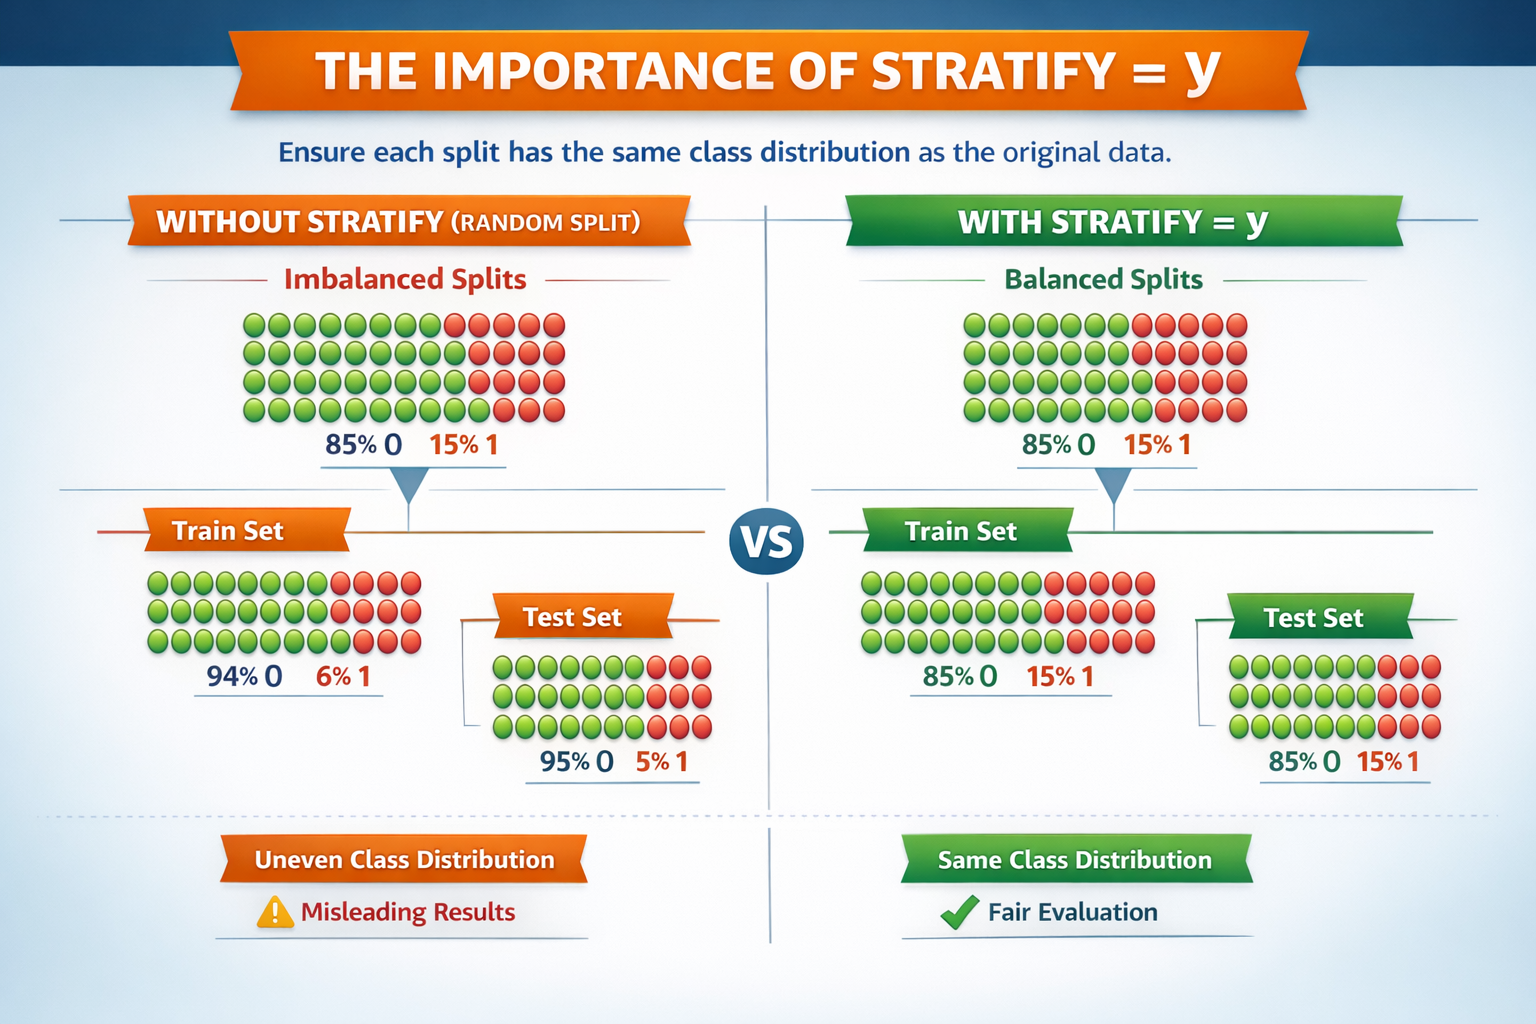

**WHY IS VALDATION TESTING REQUIRED?**

**->** to make decisions about the model(tuning) without touching the test dataset.

**The usage of these 3 datasets is different:**

The Training Dataset - Learing model parameters.

The Validation Dataset - Tuning model choices.

The Test Dataset - Fianl, unbiased evaluation.

Think of them as **study → practice → exam**.

**What goes wrong without validation?**

Scenario: Only Train + Test

Train a model

Evaluate on test set

Change hyperparameters

Evaluate again on test set

Repeat…

🔴 Problem:
You are learning from the test set indirectly.

Result:

Test accuracy becomes optimistic

Model fails on real-world data

This is called data leakage

Test set is no longer “unseen”

You’ve trained on it implicitly

**How validation fixes this**

Correct workflow

Train → Validate → Decide → Test (once)

1. Train model on training data

2. Tune:

    hyperparameters

    features

    thresholds using validation data

3. Lock the model

4. Evaluate once on test data

✔ Honest performance estimate
✔ Generalizable model

**Rule of Thumb**

Training set → learn

Validation set → decide

Test set → report

Touch the test set once. That’s it.

In [8]:
model = make_pipeline(
    SimpleImputer(strategy="median"),
    DecisionTreeClassifier(
        max_depth=25,
        random_state=42
    )
)

model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('decisiontreeclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['male','age','education',...,'BMI','heartRate','glucose']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or o

**SIMPLE IMPUTER**

👉 SimpleImputer replaces missing values (NaN) with a fixed statistical value, learned only from the training data.

It is part of data preprocessing, not modeling.

⚠️ Most ML models (including DecisionTreeClassifier) cannot handle NaNs directly.

So:

Missing values must be handled before the model sees the data.

Here the strategy we used with Simple Imputer is "median", which is the correct strategy here for our medical data. Every NaN in a column is replaced by the column's median.


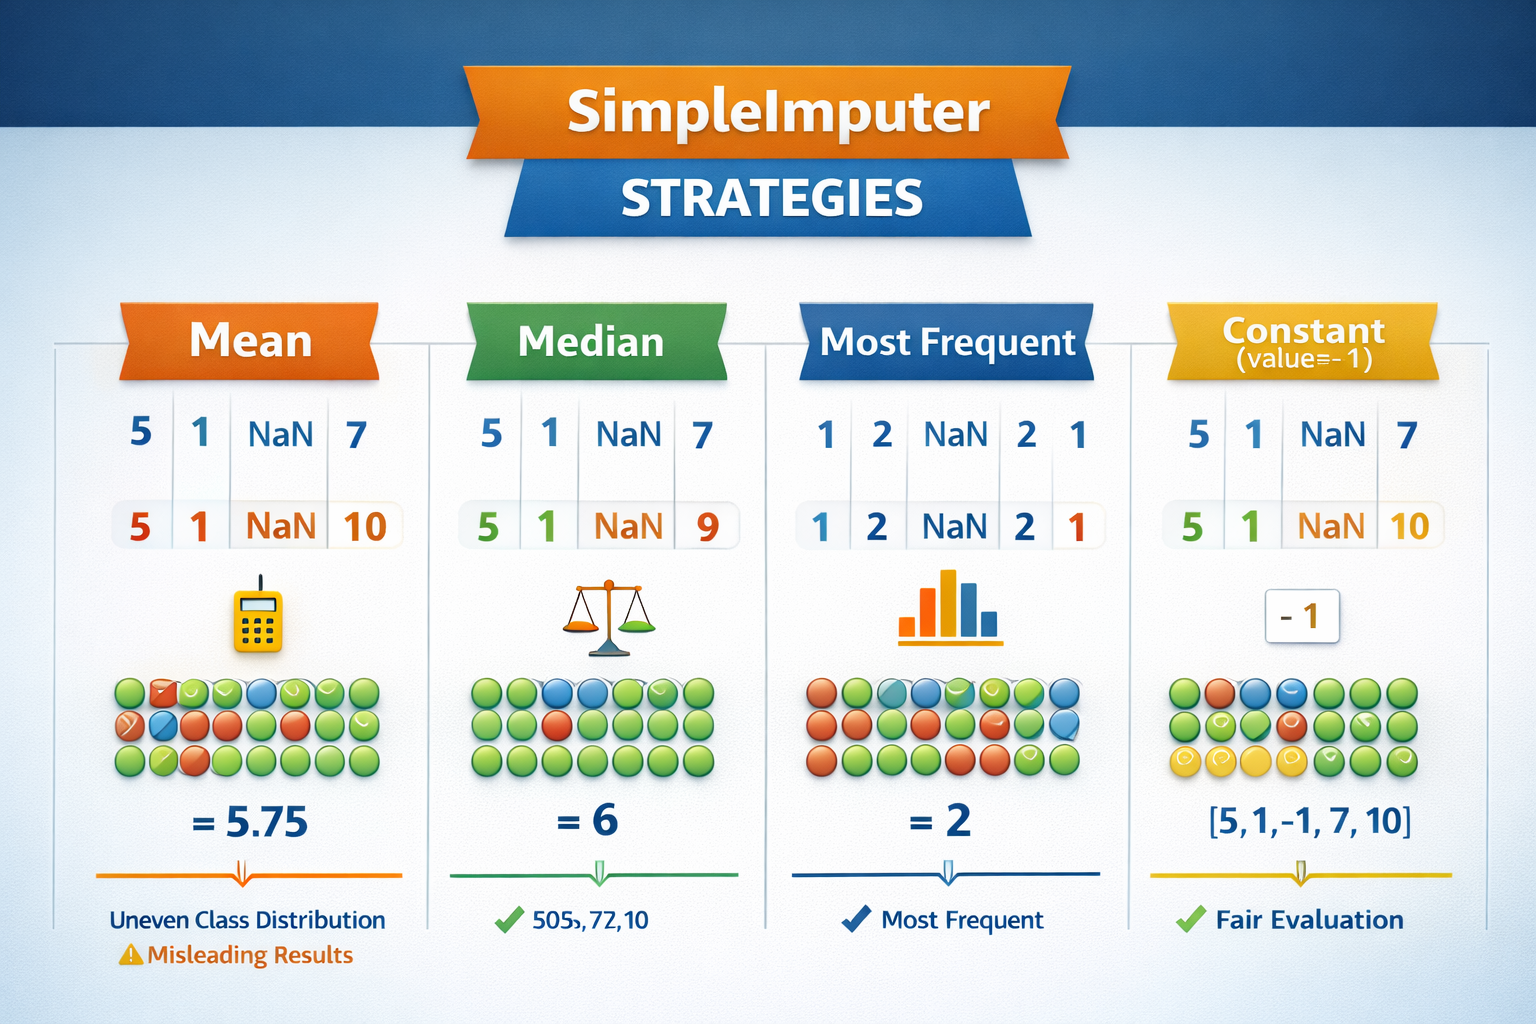

# **THE DECISION TREE CLASSIFIER**


A **Decision Tree Classifier** is a supervised machine learning algorithm that predicts a class by learning **decision rules** from data. It works like a structured flowchart of **if–else conditions**.

---

## 🌳 Visual Structure of a Decision Tree

![Image](https://images.openai.com/static-rsc-3/1dkR9kvb99D09fHyKjL7H2YFbnX6gAHa1O_9e_52ynR4nHgns1FIDnHwiAkBycIOlaAOEEePpkUmhs18uyDUCZZ5uWcpS0faRuoVdtfQCc0?purpose=fullsize\&v=1)


![Image](https://i.sstatic.net/iXc11.png)

---

## 1️⃣ Basic Idea

The tree asks questions like:

```
Is Age > 50?
    ├ Yes → Is BP > 140?
    │        ├ Yes → High Risk
    │        └ No  → Medium Risk
    └ No  → Low Risk
```

Each question splits data into smaller, more similar groups.

---

## 2️⃣ Key Components

| Component         | Meaning                        |
| ----------------- | ------------------------------ |
| **Root Node**     | First and most important split |
| **Decision Node** | Internal question              |
| **Leaf Node**     | Final prediction               |
| **Branch**        | Path based on condition        |

---

## 3️⃣ How Decision Tree Learns (Training Phase)

### Step A — Start with Full Dataset

Mixed classes (CHD = 0 and 1 together)

---

### Step B — Try All Possible Splits

For each feature, tree tries thresholds:

Example:

```
age ≤ 45
age ≤ 50
age ≤ 55
```

---

### Step C — Measure Split Quality (Impurity)

Most common metric → **Gini Impurity**

Formula:

```
Gini = 1 − Σ(p²)
```

Where p = probability of each class.

👉 Lower Gini = more pure node
👉 Tree chooses split with biggest impurity reduction

---

### Step D — Repeat Recursively

The same process repeats for each branch until stopping criteria are met.

---

## 4️⃣ Stopping Criteria (Prevents Overfitting)

Examples:

* Max depth reached
* Minimum samples per split reached
* Node becomes pure

Example from your code:

```python
DecisionTreeClassifier(max_depth=25)
```

Depth controls model complexity.

---

## 5️⃣ Prediction Phase (Very Fast ⚡)

For a new data point:

1. Start at root
2. Follow rules
3. Reach leaf
4. Output class

No heavy math — just comparisons.

---

## 6️⃣ Why It Works Well for Our Dataset

For Framingham-like medical tabular data:

✅ Handles nonlinear relations
✅ Handles feature interactions automatically
✅ Easy to interpret clinically

---

## 7️⃣ Why We Used This Pipeline

```
SimpleImputer → DecisionTreeClassifier
```

Because:

* Tree cannot handle NaNs
* Imputer fills missing values first

---

## 8️⃣ Advantages

✔ Works with numeric data directly
✔ No scaling needed
✔ Fast prediction

---

## 9️⃣ Disadvantages

❌ Can overfit (biggest issue)
❌ Unstable (small data change → new tree)
❌ Single tree weaker than ensembles

---

## 🔟 Real-Life Analogy

Doctor diagnosing patient:

* Ask symptom questions
* Narrow possibilities
* Give final diagnosis

That is exactly how a decision tree works.

In [9]:
model.score(x_val, y_val)

0.7687776141384389

In [10]:
model.score(x_train, y_train)

1.0

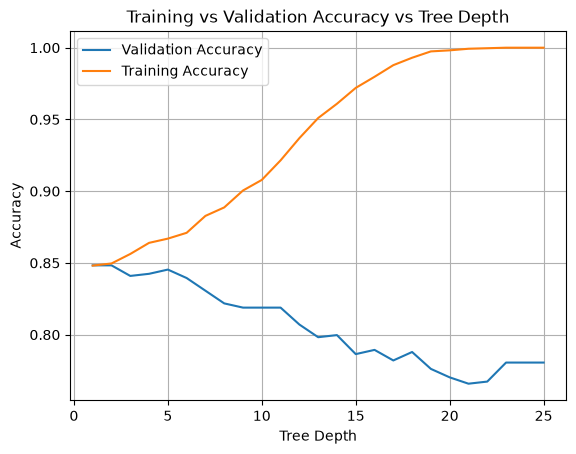

In [11]:
Val_acc = []
Train_acc = []

for d in range(1, 26):
  model = make_pipeline(SimpleImputer(), DecisionTreeClassifier(max_depth=d,random_state=42))
  model.fit(x_train, y_train)
  Val_acc.append(model.score(x_val, y_val))
  Train_acc.append(model.score(x_train, y_train))

#Now plot both lists
plt.plot(range(1, 26), Val_acc, label = "Validation Accuracy")
plt.plot(range(1, 26), Train_acc, label = "Training Accuracy")
plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy vs Tree Depth")
plt.grid()
plt.legend()


## 🔍 What The Loop Is Doing

We are testing **25 different decision trees**:

```python
for d in range(1, 26):
```

👉 Depth = 1 → very simple model
👉 Depth = 25 → very complex model

---

## 🧩 Inside Each Iteration

### 1️⃣ Build Pipeline

```python
model = make_pipeline(
    SimpleImputer(),
    DecisionTreeClassifier(max_depth=d, random_state=42)
)
```

Meaning:

* Handle missing values using **SimpleImputer**
* Train tree with **depth = d**

This matches your pipeline logic:

```
SimpleImputer → DecisionTreeClassifier
```

---

### 2️⃣ Train Model

```python
model.fit(x_train, y_train)
```

Tree learns decision rules from training data.

---

### 3️⃣ Store Validation Accuracy

```python
Val_acc.append(model.score(x_val, y_val))
```

👉 Measures **generalization performance**
👉 This is what you should optimize.

---

### 4️⃣ Store Training Accuracy

```python
Train_acc.append(model.score(x_train, y_train))
```

👉 Measures **how well model memorizes training data**

---

## 📈 What The Plot Shows

```python
plt.plot(range(1, 26), Val_acc, label="Validation Accuracy")
plt.plot(range(1, 26), Train_acc, label="Training Accuracy")
```

We will usually see:

### Case 1 — Underfitting Zone

Small depth (1–3):

* Train accuracy → Low
* Validation accuracy → Low

Model too simple.

---

### Case 2 — Good Fit Zone ⭐

Medium depth (maybe 5–10 typically):

* Train accuracy → High
* Validation accuracy → Highest

Best model lives here.

---

### Case 3 — Overfitting Zone

Large depth (15–25):

* Train accuracy → ~100%
* Validation accuracy → Drops or plateaus

Model memorizing training data.

---

## 🎯 What We Should Select

Choose depth where:

```
Validation accuracy is maximum
AND
Gap between train and validation is small
```

Not where training accuracy is highest.

---

## 🧠 What This Technique Is Called

You are performing:
👉 **Hyperparameter tuning**
👉 Specifically: **Model complexity tuning**

---

## 📌 Why This Is Important

Without this:

```python
DecisionTreeClassifier(max_depth=25)
```

We might be:

* Overfitting badly
* Getting misleading performance

---

## 🧪 Real ML Insight

Decision Trees:

* Low depth → High bias (underfit)
* High depth → High variance (overfit)

Our plot visualizes **Bias–Variance tradeoff** 📊

In [12]:
# Oversample ONLY training
# Oversampling is a data preprocessing technique used to address class imbalance, where one class (majority) heavily outnumbers another (minority),
# often in tasks like fraud detection or medical diagnosis.

over_sampler = RandomOverSampler(random_state=42)
x_train_over, y_train_over = over_sampler.fit_resample(x_train, y_train)

print("Original train shape:", x_train.shape)
print("Oversampled train shape:", x_train_over.shape)

Original train shape: (2713, 15)
Oversampled train shape: (4602, 15)


**Why Oversampling helps here**

Framingham-like dataset:

CHD positive ≈ 15%

Model may bias toward predicting 0

Oversampling:

Forces model to see more CHD cases

Improves recall for minority class

In [13]:
model2 = make_pipeline(SimpleImputer(), RandomForestClassifier())
print(model2)

Pipeline(steps=[('simpleimputer', SimpleImputer()),
                ('randomforestclassifier', RandomForestClassifier())])


**Random Forest is:**

👉 Many Decision Trees

👉 Each trained on random subset of data

👉 Final prediction = voting from all trees

🌳 Visual Idea of Random Forest

Instead of ONE tree:

Tree 1 → Predict CHD

Tree 2 → Predict CHD

Tree 3 → Predict No CHD

Tree 4 → Predict CHD

Final answer → Majority Vote

⭐ Why Random Forest Is Better Than Single Tree

Decision Tree	-> Overfits easily, High Variance, Single Decision Path

Random Forest -> Much more stable, Lower variance, Ensemble learning

In [14]:
# K Cross Validation
cv_acc_scores = cross_val_score(model2, x_train_over, y_train_over, cv = 5, n_jobs=-1)
print(cv_acc_scores)
print("Mean CV Accuracy:", cv_acc_scores.mean())

[0.97068404 0.97394137 0.97173913 0.97717391 0.97934783]
Mean CV Accuracy: 0.9745772553462683


🧠 **What Cross Validation Means**

Instead of:

👉 Training once

👉 Validating once

You now:

👉 Train 5 different times

👉 Validate 5 different times

👉 Average performance

This gives a more reliable performance estimate.

📊 How 5-Fold Cross Validation Works

Suppose training data is split into 5 parts:

Fold 1 → Test | Train Train Train Train

Fold 2 → Train | Test Train Train Train

Fold 3 → Train | Train Test Train Train

Fold 4 → Train | Train Train Test Train

Fold 5 → Train | Train Train Train Test

Each fold:

Uses different validation data

Reduces randomness bias

In [15]:
params = {
    "simpleimputer__strategy": ["mean", "median"],
    "randomforestclassifier__n_estimators": [10, 100],
    "randomforestclassifier__max_depth": [2, 10, 30]
}

In [16]:
#We'll use Grid Search CV(Cross Valuation) to calculate every possible pramaeter combination

model_main = GridSearchCV(
    model2,
    param_grid=params,
    cv=5,
    n_jobs=-1,
    verbose=1,
    scoring="roc_auc"
)

In [17]:
model_main.fit(x_train_over, y_train_over)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'randomforestclassifier__max_depth': [2, 10, ...], 'randomforestclassifier__n_estimators': [10, 100], 'simpleimputer__strategy': ['mean', 'median']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation

In [18]:
cv_results = pd.DataFrame(model_main.cv_results_)
cv_results.head(10)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_randomforestclassifier__max_depth,param_randomforestclassifier__n_estimators,param_simpleimputer__strategy,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.069012,0.012450,0.012635,0.005150,2,10,mean,"{'randomforestclassifier__max_depth': 2, 'rand...",0.721819,0.721003,0.723892,0.711628,0.707084,0.717085,0.006541,12
1,0.059411,0.002927,0.014557,0.002267,2,10,median,"{'randomforestclassifier__max_depth': 2, 'rand...",0.744921,0.716087,0.737500,0.731271,0.699979,0.725952,0.016084,11
2,0.471833,0.010035,0.037801,0.003058,2,100,mean,"{'randomforestclassifier__max_depth': 2, 'rand...",0.747913,0.722505,0.740747,0.736994,0.707479,0.731128,0.014438,9
3,0.527732,0.065190,0.034260,0.005188,2,100,median,"{'randomforestclassifier__max_depth': 2, 'rand...",0.754897,0.719438,0.734844,0.740560,0.705430,0.731034,0.017116,10
4,0.104699,0.029937,0.016860,0.003417,10,10,mean,"{'randomforestclassifier__max_depth': 10, 'ran...",0.958172,0.951797,0.937285,0.956725,0.948320,0.950460,0.007466,8
5,0.118573,0.017285,0.015925,0.003422,10,10,median,"{'randomforestclassifier__max_depth': 10, 'ran...",0.952749,0.963567,0.958058,0.965449,0.962084,0.960381,0.004525,7
6,0.987374,0.033826,0.053872,0.005692,10,100,mean,"{'randomforestclassifier__max_depth': 10, 'ran...",0.967240,0.968584,0.973459,0.985142,0.978374,0.974560,0.006588,5
7,1.029092,0.114274,0.057429,0.007695,10,100,median,"{'randomforestclassifier__max_depth': 10, 'ran...",0.969702,0.970423,0.970950,0.982533,0.972916,0.973305,0.004736,6
8,0.125688,0.019029,0.020460,0.007143,30,10,mean,"{'randomforestclassifier__max_depth': 30, 'ran...",0.990189,0.998239,0.998171,0.999350,0.999700,0.997130,0.003522,3
9,0.152062,0.022962,0.017281,0.004784,30,10,median,"{'randomforestclassifier__max_depth': 30, 'ran...",0.987284,0.998786,0.997639,0.999662,0.999251,0.996524,0.004669,4


In [19]:
best_model = model_main.best_estimator_

test_score = best_model.score(x_test, y_test)
print("Test Score:", test_score)

Test Score: 0.8384433962264151


In [ ]:
male = widgets.IntText(description="Male (0/1):")
age = widgets.IntText(description="Age:")
education = widgets.FloatText(description="Education:")
currentSmoker = widgets.IntText(description="Smoker (0/1):")
cigsPerDay = widgets.FloatText(description="Cigs/Day:")
BPMeds = widgets.IntText(description="BP Meds (0/1):")
prevalentStroke = widgets.IntText(description="Stroke (0/1):")
prevalentHyp = widgets.IntText(description="Hypertension (0/1):")
diabetes = widgets.IntText(description="Diabetes (0/1):")
totChol = widgets.FloatText(description="Cholesterol:")
sysBP = widgets.FloatText(description="Sys BP:")
diaBP = widgets.FloatText(description="Dia BP:")
BMI = widgets.FloatText(description="BMI:")
heartRate = widgets.FloatText(description="Heart Rate:")
glucose = widgets.FloatText(description="Glucose:")

predict_btn = widgets.Button(description="Predict CHD Risk")
output = widgets.Output()

In [21]:
def predict_chd(b):
    with output:
        output.clear_output()

        data = pd.DataFrame([{
            "male": male.value,
            "age": age.value,
            "education": education.value,
            "currentSmoker": currentSmoker.value,
            "cigsPerDay": cigsPerDay.value,
            "BPMeds": BPMeds.value,
            "prevalentStroke": prevalentStroke.value,
            "prevalentHyp": prevalentHyp.value,
            "diabetes": diabetes.value,
            "totChol": totChol.value,
            "sysBP": sysBP.value,
            "diaBP": diaBP.value,
            "BMI": BMI.value,
            "heartRate": heartRate.value,
            "glucose": glucose.value
        }])

        pred = best_model.predict(data)[0]

        if pred == 1:
            print("⚠ High Risk of CHD")
        else:
            print("✅ Low Risk of CHD")

In [22]:
predict_btn.on_click(predict_chd)

In [23]:
display(
    male, age, education, currentSmoker, cigsPerDay,
    BPMeds, prevalentStroke, prevalentHyp, diabetes,
    totChol, sysBP, diaBP, BMI, heartRate, glucose,
    predict_btn, output
)

IntText(value=0, description='Male (0/1):')

IntText(value=0, description='Age:')

FloatText(value=0.0, description='Education:')

IntText(value=0, description='Smoker (0/1):')

FloatText(value=0.0, description='Cigs/Day:')

IntText(value=0, description='BP Meds (0/1):')

IntText(value=0, description='Stroke (0/1):')

IntText(value=0, description='Hypertension (0/1):')

IntText(value=0, description='Diabetes (0/1):')

FloatText(value=0.0, description='Cholesterol:')

FloatText(value=0.0, description='Sys BP:')

FloatText(value=0.0, description='Dia BP:')

FloatText(value=0.0, description='BMI:')

FloatText(value=0.0, description='Heart Rate:')

FloatText(value=0.0, description='Glucose:')

Button(description='Predict CHD Risk', style=ButtonStyle())

Output()

In [24]:
import joblib

joblib.dump(best_model, "model.pkl")

print("Model Saved Successfully")

Model Saved Successfully
